## Dataset

Three CSV files were collected using the smartphone accelerometer:

- `idle.csv`
- `walking.csv`
- `situps.csv`

Each file contains:

- `time_s`: Time of the sensor reading
- `acc_x`: Acceleration along X axis
- `acc_y`: Acceleration along Y axis
- `acc_z`: Acceleration along Z axis
- `acc_abs`: Acceleration magnitude

The sampling rate is approximately 100 samples per second.

For this experiment, every 100 consecutive samples are treated as one 1-second window.

In [ ]:
# Import required libraries

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

# Reproducibility
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.20.0


In [ ]:
# File paths

IDLE_FILE = "idle.csv"
WALKING_FILE = "walking.csv"
SITUPS_FILE = "situps.csv"

# If the files are already available in Colab, this cell will load them.
# Otherwise upload them manually using the Colab file panel.

idle_df = pd.read_csv(IDLE_FILE)
walking_df = pd.read_csv(WALKING_FILE)
situps_df = pd.read_csv(SITUPS_FILE)

print("Idle shape:", idle_df.shape)
print("Walking shape:", walking_df.shape)
print("Sit-ups shape:", situps_df.shape)

display(idle_df.head())

Idle shape: (1993, 5)
Walking shape: (1994, 5)
Sit-ups shape: (1992, 5)


,time_s,acc_x,acc_y,acc_z,acc_abs
0,0.005478,-1.796564,1.638044,10.137818,10.425267
1,0.015510,-1.884731,1.676065,10.092163,10.402556
2,0.025542,-1.902993,1.742526,9.722881,10.059433
3,0.035574,-1.766926,1.720971,9.727522,10.035360
4,0.045606,-1.640888,1.582809,9.769734,10.032223


## Checking the Sensor Data

Before processing the data, we check the structure of the files.

The acceleration magnitude is calculated using:

a_mag = sqrt(acc_x² + acc_y² + acc_z²)

This gives one value representing the total acceleration at each time instant.

The CSV files already contain `acc_abs`, but we will calculate the magnitude again so that the feature extraction follows the lab question directly.

In [ ]:
# Basic dataset inspection

for name, df in {
    "Idle": idle_df,
    "Walking": walking_df,
    "Sit-ups": situps_df
}.items():

    print(f"\n{name}")
    print("-" * 40)
    print("Number of samples:", len(df))
    print("Columns:", list(df.columns))

    dt = df["time_s"].diff().dropna()

    print("Approx. sampling interval:", round(dt.median(), 6), "seconds")
    print("Approx. sampling rate:", round(1 / dt.median(), 2), "Hz")
    print("Duration:", round(df["time_s"].iloc[-1] - df["time_s"].iloc[0], 2), "seconds")


Idle
----------------------------------------
Number of samples: 1993
Columns: ['time_s', 'acc_x', 'acc_y', 'acc_z', 'acc_abs']
Approx. sampling interval: 0.010033 seconds
Approx. sampling rate: 99.67 Hz
Duration: 19.99 seconds

Walking
----------------------------------------
Number of samples: 1994
Columns: ['time_s', 'acc_x', 'acc_y', 'acc_z', 'acc_abs']
Approx. sampling interval: 0.010034 seconds
Approx. sampling rate: 99.66 Hz
Duration: 20.0 seconds

Sit-ups
----------------------------------------
Number of samples: 1992
Columns: ['time_s', 'acc_x', 'acc_y', 'acc_z', 'acc_abs']
Approx. sampling interval: 0.010036 seconds
Approx. sampling rate: 99.64 Hz
Duration: 19.98 seconds


## Feature Extraction

The continuous sensor signal is divided into windows containing 100 samples.

For every window, three features are calculated:

### 1. Mean

The mean represents the average acceleration during the window.

### 2. Standard Deviation

The standard deviation represents how much the acceleration changes during the window.

### 3. RMS

RMS represents the overall magnitude of the acceleration signal.

These three values are used as the input to the neural network.

Therefore, every 1-second sensor window becomes one row containing three features.

In [ ]:
WINDOW_SIZE = 100

def extract_features(df, label, window_size=100):
    """
    Convert raw accelerometer data into window-level features.

    Each window contains 100 samples.
    Three features are calculated:
    mean, standard deviation, RMS.
    """

    # Calculate acceleration magnitude directly from X, Y and Z
    magnitude = np.sqrt(
        df["acc_x"].values ** 2 +
        df["acc_y"].values ** 2 +
        df["acc_z"].values ** 2
    )

    features = []

    # Only use complete windows
    number_of_windows = len(magnitude) // window_size

    for i in range(number_of_windows):

        start = i * window_size
        end = start + window_size

        window = magnitude[start:end]

        mean_acc = np.mean(window)
        std_acc = np.std(window)
        rms_acc = np.sqrt(np.mean(window ** 2))

        features.append([
            mean_acc,
            std_acc,
            rms_acc,
            label
        ])

    return pd.DataFrame(
        features,
        columns=["mean", "std", "rms", "label"]
    )


idle_features = extract_features(
    idle_df,
    label="Idle",
    window_size=WINDOW_SIZE
)

walking_features = extract_features(
    walking_df,
    label="Walking",
    window_size=WINDOW_SIZE
)

situps_features = extract_features(
    situps_df,
    label="Sit-ups",
    window_size=WINDOW_SIZE
)

print("Idle windows:", len(idle_features))
print("Walking windows:", len(walking_features))
print("Sit-ups windows:", len(situps_features))

Idle windows: 19
Walking windows: 19
Sit-ups windows: 19


In [ ]:
# Combine all activity windows

feature_df = pd.concat(
    [
        idle_features,
        walking_features,
        situps_features
    ],
    ignore_index=True
)

print("Total windows:", len(feature_df))

display(feature_df.head(10))

print("\nClass distribution:")
print(feature_df["label"].value_counts())

Total windows: 57


,mean,std,rms,label
0,9.654531,0.248975,9.657740,Idle
1,9.660784,0.069491,9.661034,Idle
2,9.663004,0.059770,9.663189,Idle
3,9.666904,0.045138,9.667009,Idle
4,9.667607,0.035453,9.667672,Idle
5,9.670818,0.054533,9.670972,Idle
6,9.680418,0.040922,9.680504,Idle
7,9.685700,0.050090,9.685830,Idle
8,9.674295,0.049182,9.674420,Idle
9,9.682767,0.038925,9.682845,Idle



Class distribution:
label
Idle       19
Walking    19
Sit-ups    19
Name: count, dtype: int64


## Feature Matrix

The final dataset contains three input features:

- Mean acceleration
- Standard deviation
- RMS acceleration

The target variable is the activity class.

The activity labels are converted into numbers:

- Idle = 0
- Walking = 1
- Sit-ups = 2

The neural network will therefore perform a 3-class classification problem.

In [ ]:
# Convert class names to numerical labels

label_map = {
    "Idle": 0,
    "Walking": 1,
    "Sit-ups": 2
}

feature_df["label_id"] = feature_df["label"].map(label_map)

X = feature_df[["mean", "std", "rms"]].values.astype(np.float32)
y = feature_df["label_id"].values.astype(np.int32)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst five feature rows:")
print(X[:5])

print("\nFirst five labels:")
print(y[:5])

X shape: (57, 3)
y shape: (57,)

First five feature rows:
[[9.654531   0.24897498 9.657741  ]
 [9.660784   0.06949145 9.661034  ]
 [9.663004   0.05977019 9.663189  ]
 [9.6669035  0.04513777 9.667009  ]
 [9.667607   0.03545308 9.667672  ]]

First five labels:
[0 0 0 0 0]


## Train-Test Split

The dataset is divided into training and testing data.

The training data is used to teach the neural network.

The test data is kept separate and is used only to measure final classification performance.

Stratification is used so that all three activity classes remain represented in both sets.

In [ ]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 39
Testing samples: 18

Training class distribution:
0    13
1    13
2    13
Name: count, dtype: int64

Testing class distribution:
0    6
1    6
2    6
Name: count, dtype: int64


## Feature Scaling

The three features have different numerical ranges.

StandardScaler converts the features so that they have a similar scale.

The scaler is fitted only on the training data.

This is important because information from the test set should not be used while training the model.

In [ ]:
# Standardize features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print("Scaled training data:")
print(X_train_scaled[:5])

print("\nTraining mean:")
print(X_train_scaled.mean(axis=0))

print("\nTraining standard deviation:")
print(X_train_scaled.std(axis=0))

Scaled training data:
[[ 0.94946176  1.9262706   1.2153392 ]
 [ 0.66103506  1.1040112   0.7424657 ]
 [-0.45452845 -1.0889889  -0.5304527 ]
 [-1.0403432  -0.13731086 -1.0083888 ]
 [-0.49997622 -0.85984397 -0.5682153 ]]

Training mean:
[ 9.1699457e-09 -1.3754918e-08 -1.5283243e-08]

Training standard deviation:
[0.99999994 0.99999994 0.99999994]


## MLP Model

A small Multi-Layer Perceptron is used because the input contains only three statistical features.

The model contains:

- Input layer with 3 features
- Hidden layer with ReLU activation
- Second hidden layer with ReLU activation
- Output layer with 3 neurons

The output layer represents the three activity classes.

In [ ]:
# Build the baseline MLP

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 707 (2.76 KB)

 Trainable params: 707 (2.76 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the baseline model

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=80,
    batch_size=8,
    verbose=1
)

Epoch 1/80
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 563ms/step - accuracy: 0.3226 - loss: 1.1104 - val_accuracy: 0.5000 - val_loss: 1.0883
Epoch 2/80
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.2903 - loss: 1.0757 - val_accuracy: 0.5000 - val_loss: 1.0562
Epoch 3/80
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4194 - loss: 1.0455 - val_accuracy: 0.8750 - val_loss: 1.0261
Epoch 4/80
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5806 - loss: 1.0168 - val_accuracy: 0.7500 - val_loss: 0.9978
Epoch 5/80
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5484 - loss: 0.9897 - val_accuracy: 0.7500 - val_loss: 0.9709
Epoch 6/80
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5806 - loss: 0.9644 - val_accuracy: 0.6250 - val_loss: 0.9474
Epoch 7/80
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5484 - loss: 0.9416 - val_accuracy: 0.6250 - val_loss: 0.9245
Epoch 8/80
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5161 - loss: 0.9202 - val_accuracy: 0.6250 - val_loss: 0.9023

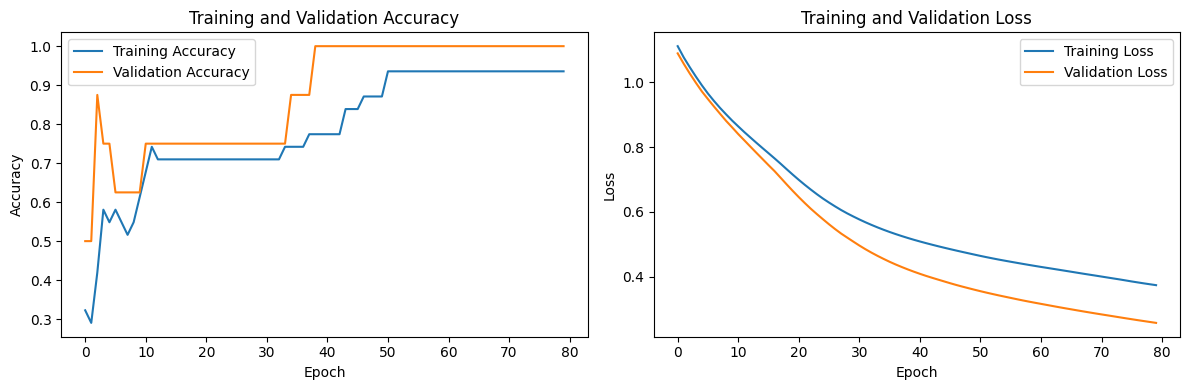

In [ ]:
# Plot training history

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

## Baseline Evaluation

The baseline model is evaluated using the test dataset.

This gives us the reference accuracy before applying quantization.

All quantized models will later be tested using exactly the same test samples.

In [ ]:
# Evaluate baseline model

baseline_loss, baseline_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Baseline Test Accuracy: {baseline_accuracy * 100:.2f}%")

# Predictions
baseline_probs = model.predict(X_test_scaled, verbose=0)
baseline_pred = np.argmax(baseline_probs, axis=1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        baseline_pred,
        target_names=["Idle", "Walking", "Sit-ups"],
        zero_division=0
    )
)

Baseline Test Accuracy: 77.78%

Classification Report:
              precision    recall  f1-score   support

        Idle       0.86      1.00      0.92         6
     Walking       1.00      0.33      0.50         6
     Sit-ups       0.67      1.00      0.80         6

    accuracy                           0.78        18
   macro avg       0.84      0.78      0.74        18
weighted avg       0.84      0.78      0.74        18



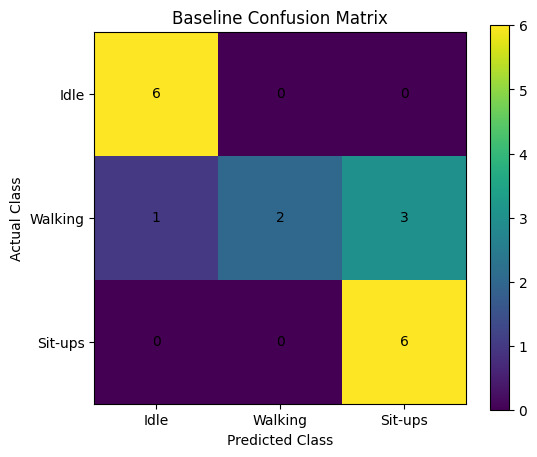

In [ ]:
# Confusion matrix

cm = confusion_matrix(y_test, baseline_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.xticks(
    [0, 1, 2],
    ["Idle", "Walking", "Sit-ups"]
)

plt.yticks(
    [0, 1, 2],
    ["Idle", "Walking", "Sit-ups"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Baseline Confusion Matrix")

for i in range(3):
    for j in range(3):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

# TensorFlow Lite Quantization

Four model versions will be created.

### Variant A: Float32 Baseline

The original neural network is stored using 32-bit floating point values.

### Variant B: Dynamic Range Quantization

The model weights are converted to 8-bit integers.

The activations remain floating point during inference.

### Variant C: Float16 Quantization

The model weights are converted from 32-bit floating point to 16-bit floating point.

This reduces storage while keeping floating point operations.

### Variant D: Full Integer Quantization

Both weights and activations are converted to 8-bit integers.

A representative dataset is required to calibrate the activation ranges.

This is the most relevant format for many microcontroller and embedded AI deployments.

In [ ]:
# Convert the baseline model to TensorFlow Lite Float32

converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_float32 = converter.convert()

with open("/content/model_float32.tflite", "wb") as f:
    f.write(tflite_float32)

print("Float32 model created.")

Saved artifact at '/tmp/tmpadvb0svk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140176772043152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772043728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044880: TensorSpec(shape=(), dtype=tf.resource, name=None)
Float32 model created.


In [ ]:
# Variant B: Dynamic Range Quantization

converter_dynamic = tf.lite.TFLiteConverter.from_keras_model(model)

converter_dynamic.optimizations = [
    tf.lite.Optimize.DEFAULT
]

tflite_dynamic = converter_dynamic.convert()

with open("/content/model_dynamic_range.tflite", "wb") as f:
    f.write(tflite_dynamic)

print("Dynamic Range model created.")

Saved artifact at '/tmp/tmprmj8j5zw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140176772043152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772043728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044880: TensorSpec(shape=(), dtype=tf.resource, name=None)
Dynamic Range model created.


In [ ]:
# Variant C: Float16 Quantization

converter_float16 = tf.lite.TFLiteConverter.from_keras_model(model)

converter_float16.optimizations = [
    tf.lite.Optimize.DEFAULT
]

converter_float16.target_spec.supported_types = [
    tf.float16
]

tflite_float16 = converter_float16.convert()

with open("/content/model_float16.tflite", "wb") as f:
    f.write(tflite_float16)

print("Float16 model created.")

Saved artifact at '/tmp/tmpm79x_jid'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140176772043152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772043728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044880: TensorSpec(shape=(), dtype=tf.resource, name=None)
Float16 model created.


## Representative Dataset for Full Integer Quantization

For full integer quantization, TensorFlow needs examples of real input data.

These examples are called the representative dataset.

The representative data is taken from the training features.

The model uses this data to determine suitable integer ranges for its inputs and intermediate activations.

In [ ]:
# Representative dataset for full integer quantization

def representative_dataset():
    # Use a subset of training data for calibration
    calibration_data = X_train_scaled[:min(100, len(X_train_scaled))]

    for sample in calibration_data:
        sample = sample.reshape(1, 3).astype(np.float32)
        yield [sample]


# Variant D: Full Integer Quantization

converter_int8 = tf.lite.TFLiteConverter.from_keras_model(model)

converter_int8.optimizations = [
    tf.lite.Optimize.DEFAULT
]

converter_int8.representative_dataset = representative_dataset

converter_int8.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8

tflite_int8 = converter_int8.convert()

with open("/content/model_full_integer_int8.tflite", "wb") as f:
    f.write(tflite_int8)

print("Full Integer INT8 model created.")

Saved artifact at '/tmp/tmptqjt8q5p'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140176772043152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772043728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140176772044880: TensorSpec(shape=(), dtype=tf.resource, name=None)
Full Integer INT8 model created.


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


## Check Model Sizes

The model file size represents the storage required by the TensorFlow Lite model.

Memory reduction is calculated relative to the original Float32 model.

Memory reduction:

Memory Reduction (%) =
((Float32 Size - Quantized Size) / Float32 Size) × 100

In [ ]:
# Model size helper

model_paths = {
    "Baseline (Unquantized)": "/content/model_float32.tflite",
    "Dynamic Range": "/content/model_dynamic_range.tflite",
    "Float16 Quantization": "/content/model_float16.tflite",
    "Full Integer (INT8)": "/content/model_full_integer_int8.tflite"
}

def get_size_kb(path):
    return os.path.getsize(path) / 1024


baseline_size_kb = get_size_kb(
    model_paths["Baseline (Unquantized)"]
)

size_results = []

for name, path in model_paths.items():

    size_kb = get_size_kb(path)

    if name == "Baseline (Unquantized)":
        reduction = 0.0
    else:
        reduction = (
            (baseline_size_kb - size_kb)
            / baseline_size_kb
        ) * 100

    size_results.append({
        "Quantization Scheme": name,
        "Model Size (KB)": size_kb,
        "Memory Reduction (%)": reduction
    })

size_df = pd.DataFrame(size_results)

display(size_df)

,Quantization Scheme,Model Size (KB),Memory Reduction (%)
0,Baseline (Unquantized),4.812500,0.000000
1,Dynamic Range,4.812500,0.000000
2,Float16 Quantization,4.191406,12.905844
3,Full Integer (INT8),4.367188,9.253247


### Why Dynamic Range Quantization Shows 0% Memory Reduction

Dynamic Range Quantization converts the model weights from Float32 to INT8. However, the model used in this experiment is very small, so the weight data occupies only a small portion of the total TFLite file.

The TFLite model also contains fixed overhead such as model structure, tensor information, operators, and metadata. These additional components are not reduced by Dynamic Range Quantization.

Therefore, although the weights are quantized, the overall `.tflite` file size remains approximately the same at 4.8125 KB, resulting in a measured memory reduction of 0%.

This effect is mainly due to the very small size of the MLP model. Larger neural networks would generally show a more noticeable reduction in model size.

# TensorFlow Lite Inference Benchmark

The next step is to test all four TensorFlow Lite models.

For every model we measure:

- Classification accuracy
- Average inference time
- Model file size
- Memory reduction

The same test dataset is used for every model so that the comparison is fair.

In [ ]:
  # Helper function for TFLite model information

def get_tflite_details(model_path):
    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    return interpreter, input_details, output_details


for name, path in model_paths.items():

    interpreter, input_details, output_details = get_tflite_details(path)

    print("\n", name)
    print("Input:")
    print(input_details[0])

    print("Output:")
    print(output_details[0])


 Baseline (Unquantized)
Input:
{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([1, 3], dtype=int32), 'shape_signature': array([-1,  3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}
Output:
{'name': 'StatefulPartitionedCall_1:0', 'index': 10, 'shape': array([1, 3], dtype=int32), 'shape_signature': array([-1,  3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}

 Dynamic Range
Input:
{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([1, 3], dtype=int32), 'shape_signature': array([-1,  3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_paramete

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## TFLite Prediction Function

Float32, Dynamic Range, and Float16 models normally accept floating point input.

The Full Integer model accepts int8 input.

Therefore, the input must be converted using the quantization scale and zero point stored inside the TFLite model.

In [ ]:
def quantize_input(x, input_detail):
    """
    Convert float input to the datatype expected by TFLite.
    """

    dtype = input_detail["dtype"]

    if dtype == np.float32:
        return x.astype(np.float32)

    scale, zero_point = input_detail["quantization"]

    if scale == 0:
        raise ValueError("Invalid quantization scale.")

    q = np.round(x / scale + zero_point)

    if dtype == np.int8:
        q = np.clip(q, -128, 127)

    elif dtype == np.uint8:
        q = np.clip(q, 0, 255)

    return q.astype(dtype)


def dequantize_output(output, output_detail):
    """
    Convert quantized TFLite output back to floating point.
    """

    dtype = output_detail["dtype"]

    if dtype == np.float32:
        return output

    scale, zero_point = output_detail["quantization"]

    return (output.astype(np.float32) - zero_point) * scale

In [ ]:
def predict_tflite(model_path, X_data):
    """
    Run prediction for every sample in X_data.
    """

    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()

    input_detail = interpreter.get_input_details()[0]
    output_detail = interpreter.get_output_details()[0]

    predictions = []

    for sample in X_data:

        input_data = sample.reshape(1, -1).astype(np.float32)

        input_data = quantize_input(
            input_data,
            input_detail
        )

        interpreter.set_tensor(
            input_detail["index"],
            input_data
        )

        interpreter.invoke()

        output = interpreter.get_tensor(
            output_detail["index"]
        )

        output = dequantize_output(
            output,
            output_detail
        )

        predictions.append(
            np.argmax(output, axis=1)[0]
        )

    return np.array(predictions)

In [ ]:
# Test classification accuracy for every TFLite model

accuracy_results = []

for name, path in model_paths.items():

    predictions = predict_tflite(
        path,
        X_test_scaled
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    ) * 100

    accuracy_results.append({
        "Quantization Scheme": name,
        "Accuracy (%)": accuracy
    })

    print(
        f"{name}: "
        f"{accuracy:.2f}%"
    )

accuracy_df = pd.DataFrame(accuracy_results)

display(accuracy_df)

Baseline (Unquantized): 77.78%
Dynamic Range: 77.78%
Float16 Quantization: 77.78%
Full Integer (INT8): 77.78%


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

,Quantization Scheme,Accuracy (%)
0,Baseline (Unquantized),77.777778
1,Dynamic Range,77.777778
2,Float16 Quantization,77.777778
3,Full Integer (INT8),77.777778


## Inference Latency

Inference latency is the time required by the model to classify one input window.

The value is measured in microseconds.

A lower value means the model completed inference faster on the current machine.

The exact latency depends on the hardware running this notebook. Therefore, the latency measured in Google Colab represents the Colab environment and should not be treated as the exact latency of the final microcontroller.

In [ ]:
def benchmark_latency(model_path, X_data, warmup=20, repetitions=100):
    """
    Measure average TFLite inference time per sample.

    The model is warmed up first to reduce initialization effects.
    """

    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()

    input_detail = interpreter.get_input_details()[0]
    output_detail = interpreter.get_output_details()[0]

    # Warm-up
    for sample in X_data[:min(warmup, len(X_data))]:

        input_data = sample.reshape(1, -1).astype(np.float32)

        input_data = quantize_input(
            input_data,
            input_detail
        )

        interpreter.set_tensor(
            input_detail["index"],
            input_data
        )

        interpreter.invoke()

    # Timed inference
    times = []

    for i in range(repetitions):

        sample = X_data[i % len(X_data)]

        input_data = sample.reshape(1, -1).astype(np.float32)

        input_data = quantize_input(
            input_data,
            input_detail
        )

        start = time.perf_counter()

        interpreter.set_tensor(
            input_detail["index"],
            input_data
        )

        interpreter.invoke()

        _ = interpreter.get_tensor(
            output_detail["index"]
        )

        end = time.perf_counter()

        times.append(
            (end - start) * 1_000_000
        )

    return np.mean(times), np.std(times)

In [ ]:

# Benchmark all four models

latency_results = []

for name, path in model_paths.items():

    mean_latency, std_latency = benchmark_latency(
        path,
        X_test_scaled,
        warmup=20,
        repetitions=200
    )

    latency_results.append({
        "Quantization Scheme": name,
        "Average Inference Time (us)": mean_latency,
        "Latency Std (us)": std_latency
    })

    print(
        f"{name}: "
        f"{mean_latency:.2f} us "
        f"(std: {std_latency:.2f} us)"
    )

latency_df = pd.DataFrame(latency_results)

display(latency_df)

Baseline (Unquantized): 4.82 us (std: 1.58 us)
Dynamic Range: 4.64 us (std: 2.19 us)
Float16 Quantization: 5.68 us (std: 5.55 us)
Full Integer (INT8): 6.36 us (std: 3.64 us)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Quantization Scheme,Average Inference Time (us),Latency Std (us)
0,Baseline (Unquantized),4.824585,1.581038
1,Dynamic Range,4.641460,2.189716
2,Float16 Quantization,5.679690,5.548120
3,Full Integer (INT8),6.355700,3.635700


### Why Inference Time Increased After Quantization

Quantization does not always make inference faster, especially for a very small model.

In this experiment, the Float32 model has an average inference time of 4.82 µs, while the Dynamic Range, Float16, and Full Integer models show different latency values. The Full Integer model has the highest measured latency at 6.36 µs.

This happens because the experiment is running on Google Colab's CPU, not on a microcontroller or dedicated INT8 hardware. The model is also extremely small, so the computational savings from using smaller data types are very small. Additional operations such as quantization, dequantization, data type conversion, and TensorFlow Lite interpreter overhead can take more time than the actual neural network computation.

Therefore, the higher latency does not mean that quantization is ineffective. Quantization primarily reduces memory and model size, while inference speed improvements depend strongly on the target hardware and its support for optimized INT8 operations.

The measured latency should therefore be interpreted as the performance on the current Colab environment. Actual embedded hardware may show different results.

# Final Quantization Comparison and Analysis

| Quantization Scheme | Target Data Type | Model Size (KB) | Accuracy (%) | Memory Reduction (%) | Average Inference Time (µs) |
|---|---|---:|---:|---:|---:|
| Baseline (Unquantized) | Float32 | 4.812500 | 77.777778 | 0.000000 | 4.824585 |
| Dynamic Range | Weights int8, Activations float32 | 4.812500 | 77.777778 | 0.000000 | 4.641460 |
| Float16 Quantization | Float16 | 4.191406 | 77.777778 | 12.905844 | 5.679690 |
| Full Integer (PTQ) | Weights int8, Activations int8 | 4.367188 | 77.777778 | 9.253247 | 6.355700 |

### Accuracy

All four models achieved the same accuracy of 77.78% because quantization introduced only small numerical changes that did not change the predicted class for the test samples.

The small MLP and simple statistical features also make the model relatively insensitive to the precision reduction.

### Model Size

Float16 reduced the model size by 12.91%, while Full Integer reduced it by 9.25%.

Dynamic Range showed no overall file-size reduction because the model is very small and the fixed TensorFlow Lite overhead is significant compared with the weight storage.

### Memory Reduction

The Dynamic Range model showed 0% measured file-size reduction because the quantized weights are a small part of the total TFLite file.

Float16 and Full Integer quantization reduced the overall file size, with Float16 giving the largest reduction in this experiment.

### Average Inference Time

The inference time did not consistently decrease after quantization because the model is very small and the experiment was executed on a Google Colab CPU rather than optimized embedded INT8 hardware.

Additional datatype conversion and TensorFlow Lite interpreter overhead can therefore outweigh the computational benefit of quantization for this small model.